In [1]:
import pandas as pd

In [2]:
#feature Engineering
df=pd.read_csv('raw_data.csv')
df2 = df.copy()
df2['tax']=df2['income'].apply(lambda x : '20%' if x>=60000 else '10%')
gender_map = {'Male':'M','female':'F','Unknown': 'U'}
df2['gender'] = df2['gender'].map(gender_map)
df2.assign(new_income = df2['income']*1.1)
df2['country'] = df2['country'].replace('USA', 'US')

In [24]:
# df2.columns=['Id','Name','Age','Country','Gender','Income','Tax','New_Income']
df2.rename(columns={'income':'Salary'})
df2.rename(index={1:'first'})
df2=df2.fillna(50)
df2.sort_values('income',ascending=False)
sorted_df = df2.sort_values(['income','age'])

sorted_df.sort_index()

#reset
sorted_df.reset_index()
sorted_df.reset_index(drop=True)

#Ranking
sorted_df['Ranking'] = sorted_df['income'].rank(ascending = False,method='max')
sorted_df[['id','nam']]


In [18]:
df2

,id,name,age,country,gender,income,tax
0,1,John Doe,29.0,US,M,55000.0,10%
1,1,John Doe,29.0,US,M,55000.0,10%
2,2,Jane Smith,50.0,Canada,50,62000.0,20%
3,3,Alex,50.0,US,U,47000.0,10%
4,4,Maria Garcia,34.0,Spain,50,50.0,10%
5,5,Li Wei,27.0,China,M,51000.0,10%
6,6,50,45.0,India,50,73000.0,20%
7,7,Ahmed Khan,38.0,50,M,68000.0,20%
8,8,Rachel Lee,29.0,US,50,62000.0,20%
9,9,Carlos Ruiz,50.0,Mexico,M,45000.0,10%


In [4]:
#Task -> Shift id column to the end
df2=df.copy()
new_col_order = [col for col in df2.columns if col!='id'] + ['id']
print(new_col_order)
df2[new_col_order]

['name', 'age', 'country', 'gender', 'income', 'id']


,name,age,country,gender,income,id
0,John Doe,29.0,USA,Male,55000.0,1
1,John Doe,29.0,USA,Male,55000.0,1
2,Jane Smith,NaN,Canada,Female,62000.0,2
3,Alex,NaN,USA,Unknown,47000.0,3
4,Maria Garcia,34.0,Spain,Female,NaN,4
5,Li Wei,27.0,China,Male,51000.0,5
6,NaN,45.0,India,Female,73000.0,6
7,Ahmed Khan,38.0,NaN,Male,68000.0,7
8,Rachel Lee,29.0,USA,Female,62000.0,8
9,Carlos Ruiz,NaN,Mexico,Male,45000.0,9


In [5]:
#storing data to csv

df2 = df.copy()

df2 = df2.drop_duplicates()
df2 = df2.fillna(0)

df2 = df2.sort_values('income')
df2 = df2.reset_index(drop = True)

df2.to_csv('sorted_data.csv')

In [15]:
#grouping and aggrigation

df.groupby('country')['income'].mean()
df.groupby('country')['income'].max()
df.groupby('country')['income'].min()

df.groupby('gender')['income'].max()
df.groupby('gender')['income'].min()

df.groupby('country')['income'].agg(['mean','min','max'])
df.groupby('country')['income'].aggregate(['mean','min','max'])

df.groupby('country')['income'].agg(avg_salary='mean',min_salary='min',max_salary='max')

df.groupby('country').agg({
    'income':'mean',
    'age':'max'
})

df.groupby('country').agg(
    max_salary=('income','max'),
    avg_age=('age','mean')
)

,max_salary,avg_age
country,,
Canada,62000.0,NaN
China,51000.0,27.0
India,73000.0,45.0
Mexico,45000.0,NaN
Spain,NaN,34.0
USA,62000.0,29.5


In [19]:
#melt & pivot for reshaping
df = pd.DataFrame({
    'country':['USA','USA','India','India'],
    'sales':[2000,1000,3000,40000],
    'year':[2022,2011,2000,2030],
    'profit':[20,30,50,55],
    'tax':[5,6,7,8]
})

melted_df=df.melt(
    id_vars = ['country','year'],
    value_vars = ['sales','profit','tax'],
    var_name = 'metrices',
    value_name = 'value'
)

melted_df.pivot(
    index = ['country','year'],   #index should be unique that is why took both year and country
    columns = 'metrices',
    values = 'value'
)

metrices      profit  sales  tax
country year                    
India   2000      50   3000    7
        2030      55  40000    8
USA     2011      30   1000    6
        2022      20   2000    5

<Axes: xlabel='Age', ylabel='Salary'>

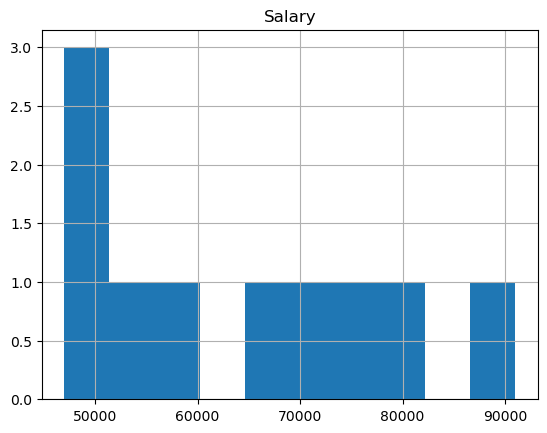

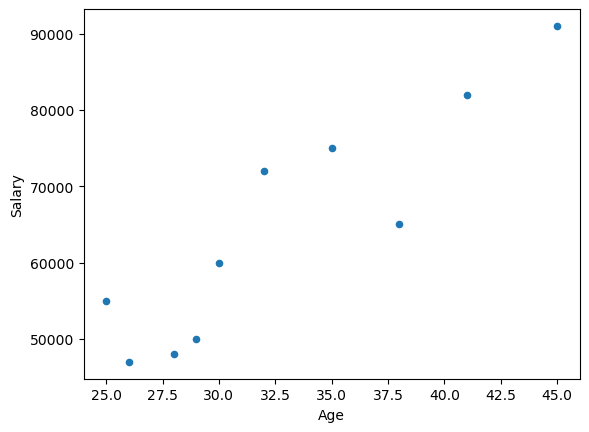

In [26]:
#Basic Visualization
df=pd.read_csv('employee_data.csv')
df.hist('Salary')
df.plot(kind='scatter',x='Age', y='Salary')

In [29]:
#merging & joining data

df_customers = pd.DataFrame({
    'customer_id':[1,2,3,4],
    'name':['Aryan','Abl','bob','Adam']
})

df_orders = pd.DataFrame({
    'order_id':[101,102,103,333],
    'customer_id':[2,1,4,5],
    'amount':[3,1,3,0]
}) 

In [33]:
pd.merge(df_customers,df_orders,on='customer_id') #inner join
pd.merge(df_customers,df_orders,on='customer_id',how='left') #left join
pd.merge(df_customers,df_orders,on='customer_id' ,how ='right') #right join
pd.merge(df_customers,df_orders,on='customer_id', how = 'outer') #outer join

,customer_id,name,order_id,amount
0,1,Aryan,102.0,1.0
1,2,Abl,101.0,3.0
2,3,bob,NaN,NaN
3,4,Adam,103.0,3.0
4,5,NaN,333.0,0.0


In [36]:
#concatination
df1 = pd.DataFrame({
    'id':[1,2,3],
    'name':['adam','bob','eve']
})
df2= pd.DataFrame({
    'id':[4,5,6],
    'name':['fren','zack','tony']
})

pd.concat([df1,df2]) #row concatination
pd.concat([df1,df2],ignore_index=True) #get new index values

pd.concat([df1,df2],axis=1)  #column concatination

,id,name,id,name
0,1,adam,4,fren
1,2,bob,5,zack
2,3,eve,6,tony
